# Simulación de Parqueaderos — Centro Comercial Supercentro (Módulo 4 – ACT 2)

**Integrantes:** Raul Santiago Morales Henao y David Octavio Castro Mora  
**Repositorio GitHub:** [Ver repositorio del proyecto](https://github.com/shenao356/simulacion-parqueaderos-supercentro)  
**Abrir en Google Colab:** [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shenao356/simulacion-parqueaderos-supercentro/blob/main/notebooks/Simulacion_Parqueaderos_Supercentro.ipynb)

Cuaderno resumido y 100 % sincronizado con `src/simulacion.py` y el informe en formato APA 7.

## 1. Configuración e Importación del Código del Repositorio

In [1]:
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

REPO_URL = 'https://github.com/shenao356/simulacion-parqueaderos-supercentro.git'
REPO_DIR = Path('simulacion-parqueaderos-supercentro')

if Path('src/simulacion.py').exists():
    ROOT = Path('.').resolve()
elif Path('../src/simulacion.py').exists():
    ROOT = Path('..').resolve()
else:
    # En Google Colab: instala SimPy en este intérprete y descarga la versión actual del repo
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'simpy'])
    if REPO_DIR.exists():
        shutil.rmtree(REPO_DIR)
    subprocess.check_call(['git', 'clone', '--depth', '1', '-q', REPO_URL, str(REPO_DIR)])
    ROOT = REPO_DIR.resolve()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

for _m in [m for m in list(sys.modules) if m == 'src' or m.startswith('src.')]:
    del sys.modules[_m]

import pandas as pd
from IPython.display import Image, display
from src.simulacion import (
    EQUIPO_TRABAJO, PERFILES_USUARIO, parametros_teoricos,
    calcular_estado_estable, eliminar_estado_transitorio,
    analizar_puntos_a_y_b, evaluar_estrategias, validar_modelo_vcv,
)
from src.graficas import (
    graficar_estado_estable, graficar_cajeros_y_usuarios,
    graficar_estrategias, graficar_vcv, graficar_transitorio_antes_despues,
)

OUT_FIG = Path(tempfile.gettempdir()) / 'figuras_supercentro'
OUT_FIG.mkdir(parents=True, exist_ok=True)
print('Integrantes:', ' | '.join(EQUIPO_TRABAJO))
display(pd.DataFrame(PERFILES_USUARIO))
teo = parametros_teoricos()
print(f"E[S]={teo['E_S']:.2f} min | E[A]={teo['E_A']:.2f} min | ρ={teo['rho']*100:.2f} % | Demanda={teo['demanda_hora_total']:.1f} usr/h")

Integrantes: Raul Santiago Morales Henao | David Octavio Castro Mora


,nombre,prob,servicio,llegada
0,Rápido,0.250,1.0,3.0
1,Normal,0.200,3.0,3.0
2,Lento,0.275,4.0,5.0
3,Muy lento,0.275,6.0,7.0


E[S]=3.60 min | E[A]=4.65 min | ρ=77.42 % | Demanda=38.7 usr/h


## 2. Identificación del Estado Estable (`R*`)

Réplicas seleccionadas: R* = 160 (W = 18.60 min, error = 3.04 %)


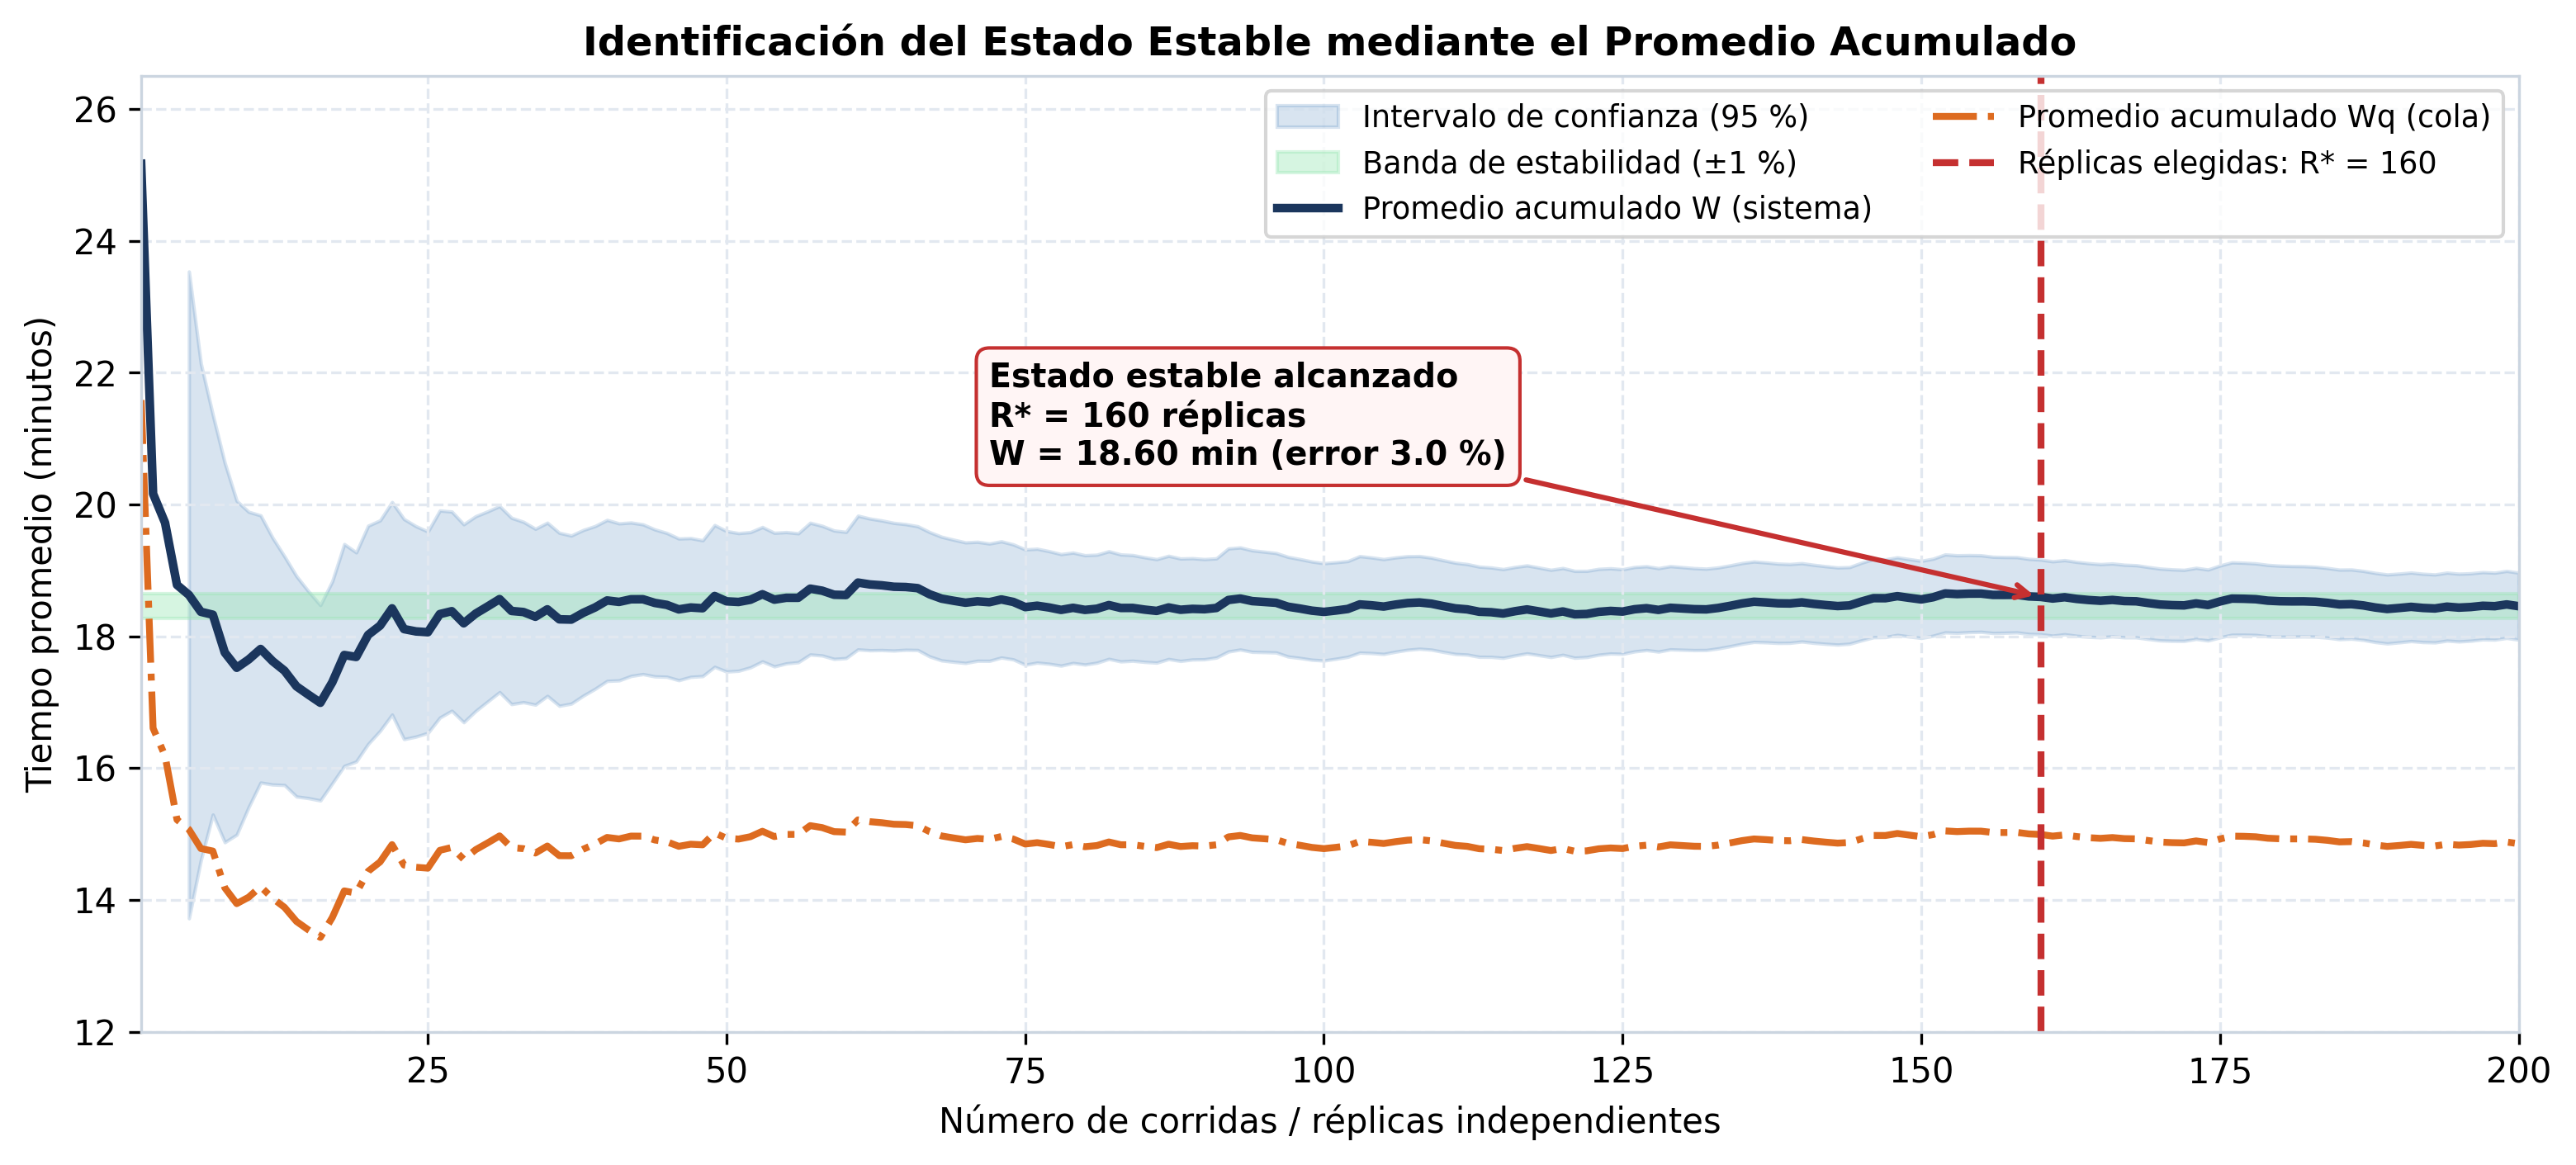

In [2]:
df_conv, res_est = calcular_estado_estable()
R_OPT = res_est['r_optimo']
print(f"Réplicas seleccionadas: R* = {R_OPT} (W = {res_est['W_en_r']:.2f} min, error = {res_est['error_rel_pct']:.2f} %)")
display(Image(filename=str(graficar_estado_estable(df_conv, res_est, OUT_FIG)), width=800))

## 3. Punto E — Algoritmo de Eliminación del Estado Transitorio (Antes vs. Después)

Corte óptimo detectado: t0* = 390 min (16.2 % del horizonte)


,Metrica,Antes,Despues,Cambio_pct
0,"Tiempo de espera en cola (Wq, min)",14.99,15.67,4.51
1,"Tiempo total en sistema (W, min)",18.60,19.28,3.67
2,"Tiempo de servicio en cajero (S, min)",3.60,3.61,0.18
3,"Longitud promedio de cola (Lq, usuarios)",3.23,3.40,5.27
4,Utilización del cajero (ρ),0.77,0.78,0.88


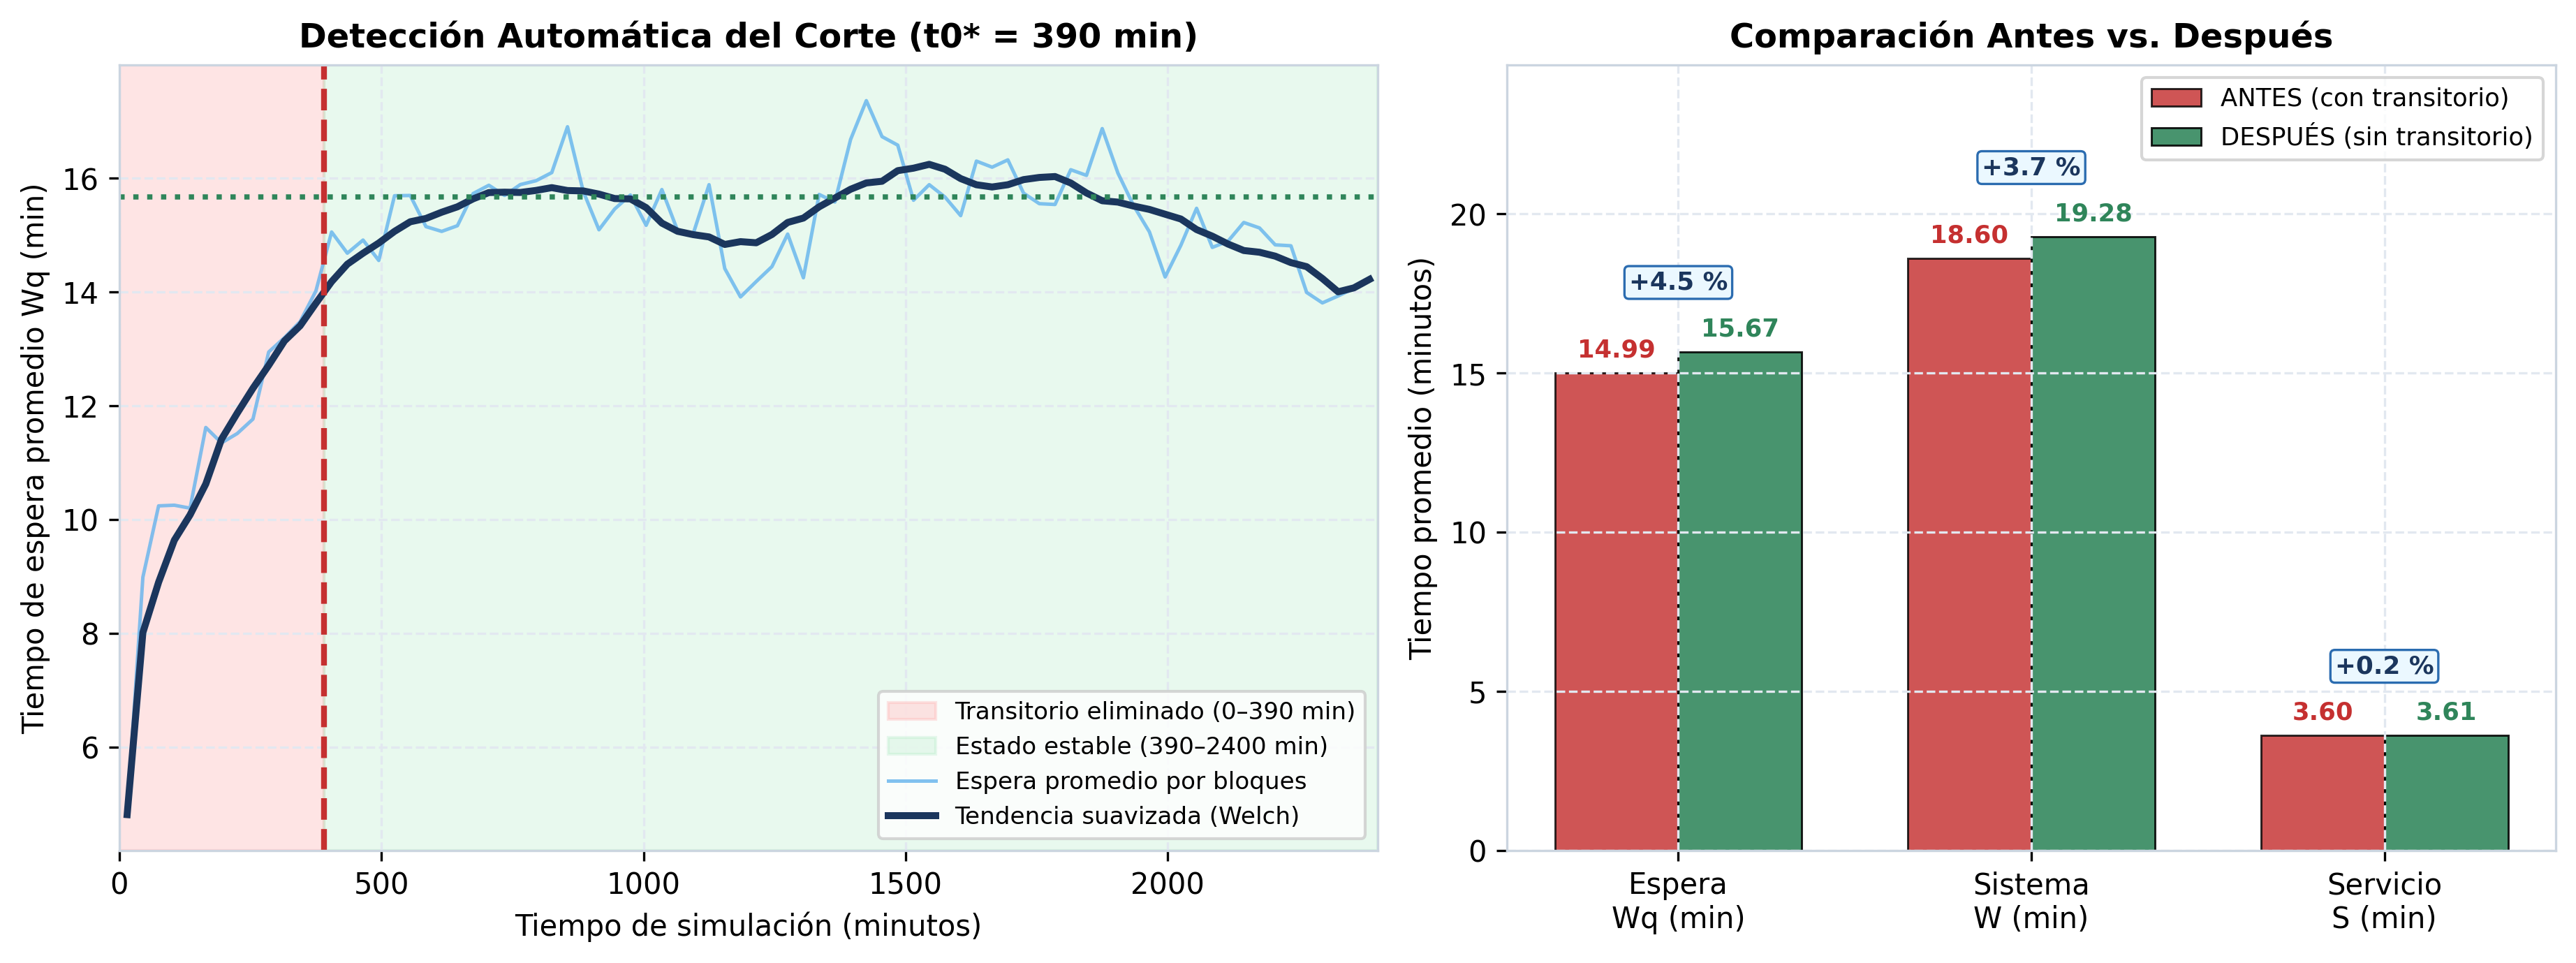

In [3]:
res_t = eliminar_estado_transitorio(R_OPT)
T0 = res_t['t0_min']
print(f"Corte óptimo detectado: t0* = {T0:.0f} min ({res_t['pct_descartado']:.1f} % del horizonte)")
display(res_t['df_comparacion'][['Metrica', 'Antes', 'Despues', 'Cambio_pct']].round(2))
display(Image(filename=str(graficar_transitorio_antes_despues(res_t, OUT_FIG)), width=840))

## 4. Puntos A y B — Estadísticas por Cajero y Promedio de Usuarios por Tipo

Punto A -> Menor W: Cajero 3 (19.08 min) | Mayor W: Cajero 2 (19.41 min) | ANOVA p = 0.914


,Cajero,Servicio_S_min,Espera_Wq_min,Total_W_min,Desv_W_min,Cola_Lq,Utilizacion_pct,Atendidos
0,Cajero 1,3.61,15.74,19.35,8.10,3.43,77.83,433.25
1,Cajero 2,3.58,15.82,19.41,7.90,3.45,77.48,434.44
2,Cajero 3,3.63,15.44,19.08,6.31,3.34,77.86,430.87


,Tipo_usuario,Promedio_3_cajeros,Promedio_por_cajero,Usuarios_por_hora,Porcentaje_simulado,Porcentaje_teorico
0,Rápido,324.87,108.29,9.70,25.02,25.0
1,Normal,259.81,86.60,7.76,20.01,20.0
2,Lento,354.98,118.33,10.60,27.34,27.5
3,Muy lento,358.90,119.63,10.71,27.64,27.5
4,TOTAL SISTEMA,1298.56,432.85,38.76,100.00,100.0


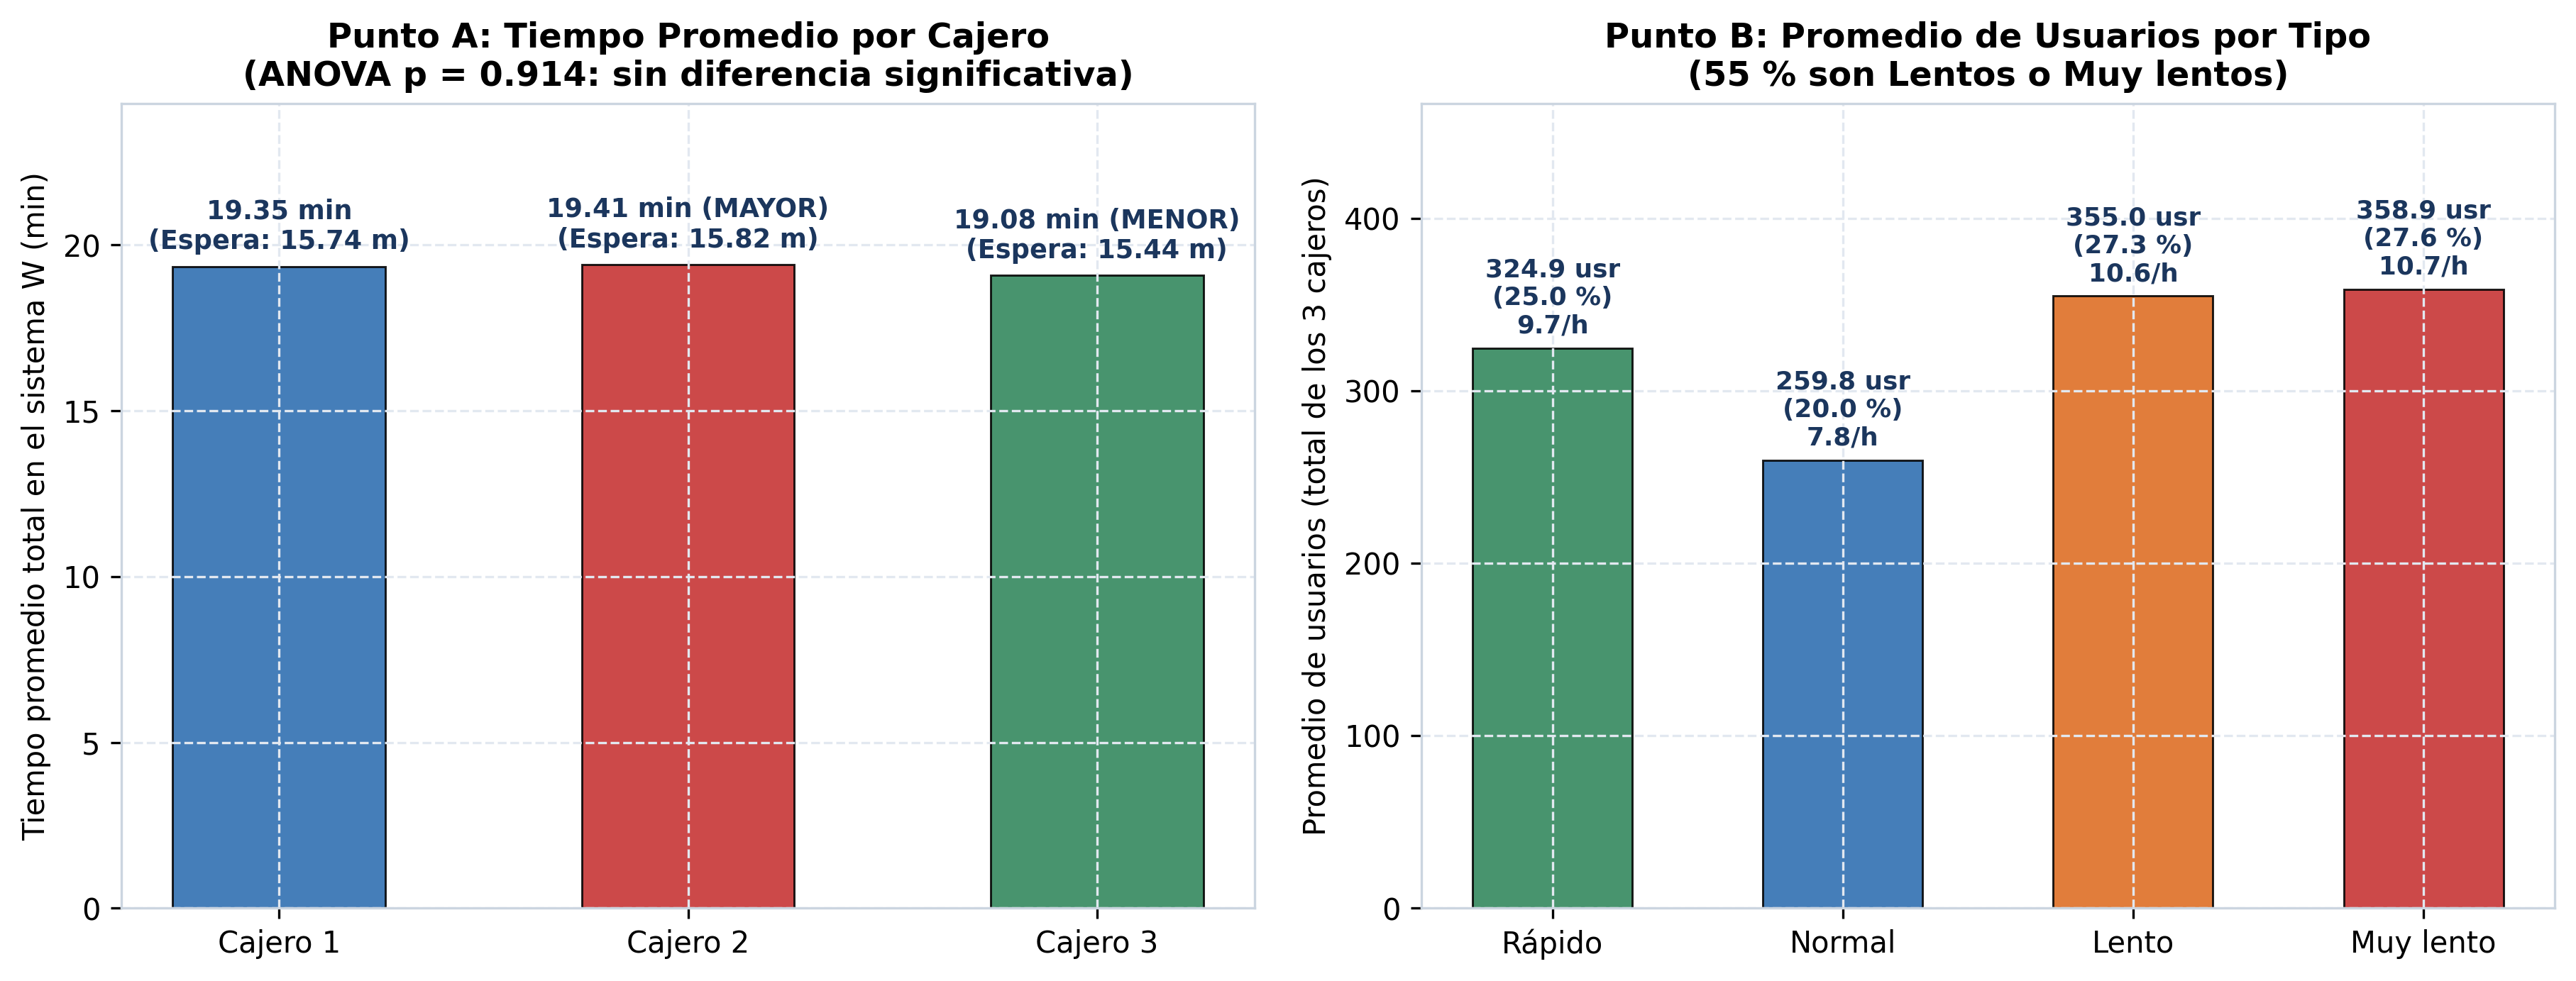

In [4]:
res_a, df_b = analizar_puntos_a_y_b(res_t['df_despues'], res_t['ventana_estable_min'])
print(f"Punto A -> Menor W: {res_a['menor_cajero']} ({res_a['menor_W']:.2f} min) | Mayor W: {res_a['mayor_cajero']} ({res_a['mayor_W']:.2f} min) | ANOVA p = {res_a['anova_p_W']:.3f}")
display(res_a['tabla'].round(2))
display(df_b.round(2))
display(Image(filename=str(graficar_cajeros_y_usuarios(res_a, df_b, OUT_FIG)), width=840))

## 5. Punto C — Evaluación de Estrategias de Mejora

,Escenario,Espera_Wq_min,Total_W_min,Utilizacion_pct,Reduccion_Wq_pct,Criterios_SLA
0,Actual: 3 cajeros (filas separadas),15.67,19.28,77.72,0.00,0/3
1,Opción 1: 4 cajeros (filas separadas),6.58,10.18,58.40,58.01,1/3
2,Opción 2: 3 cajeros (fila única),4.04,7.65,77.74,74.19,2/3
3,Recomendada: 4 cajeros (fila única),0.71,4.32,58.29,95.46,3/3


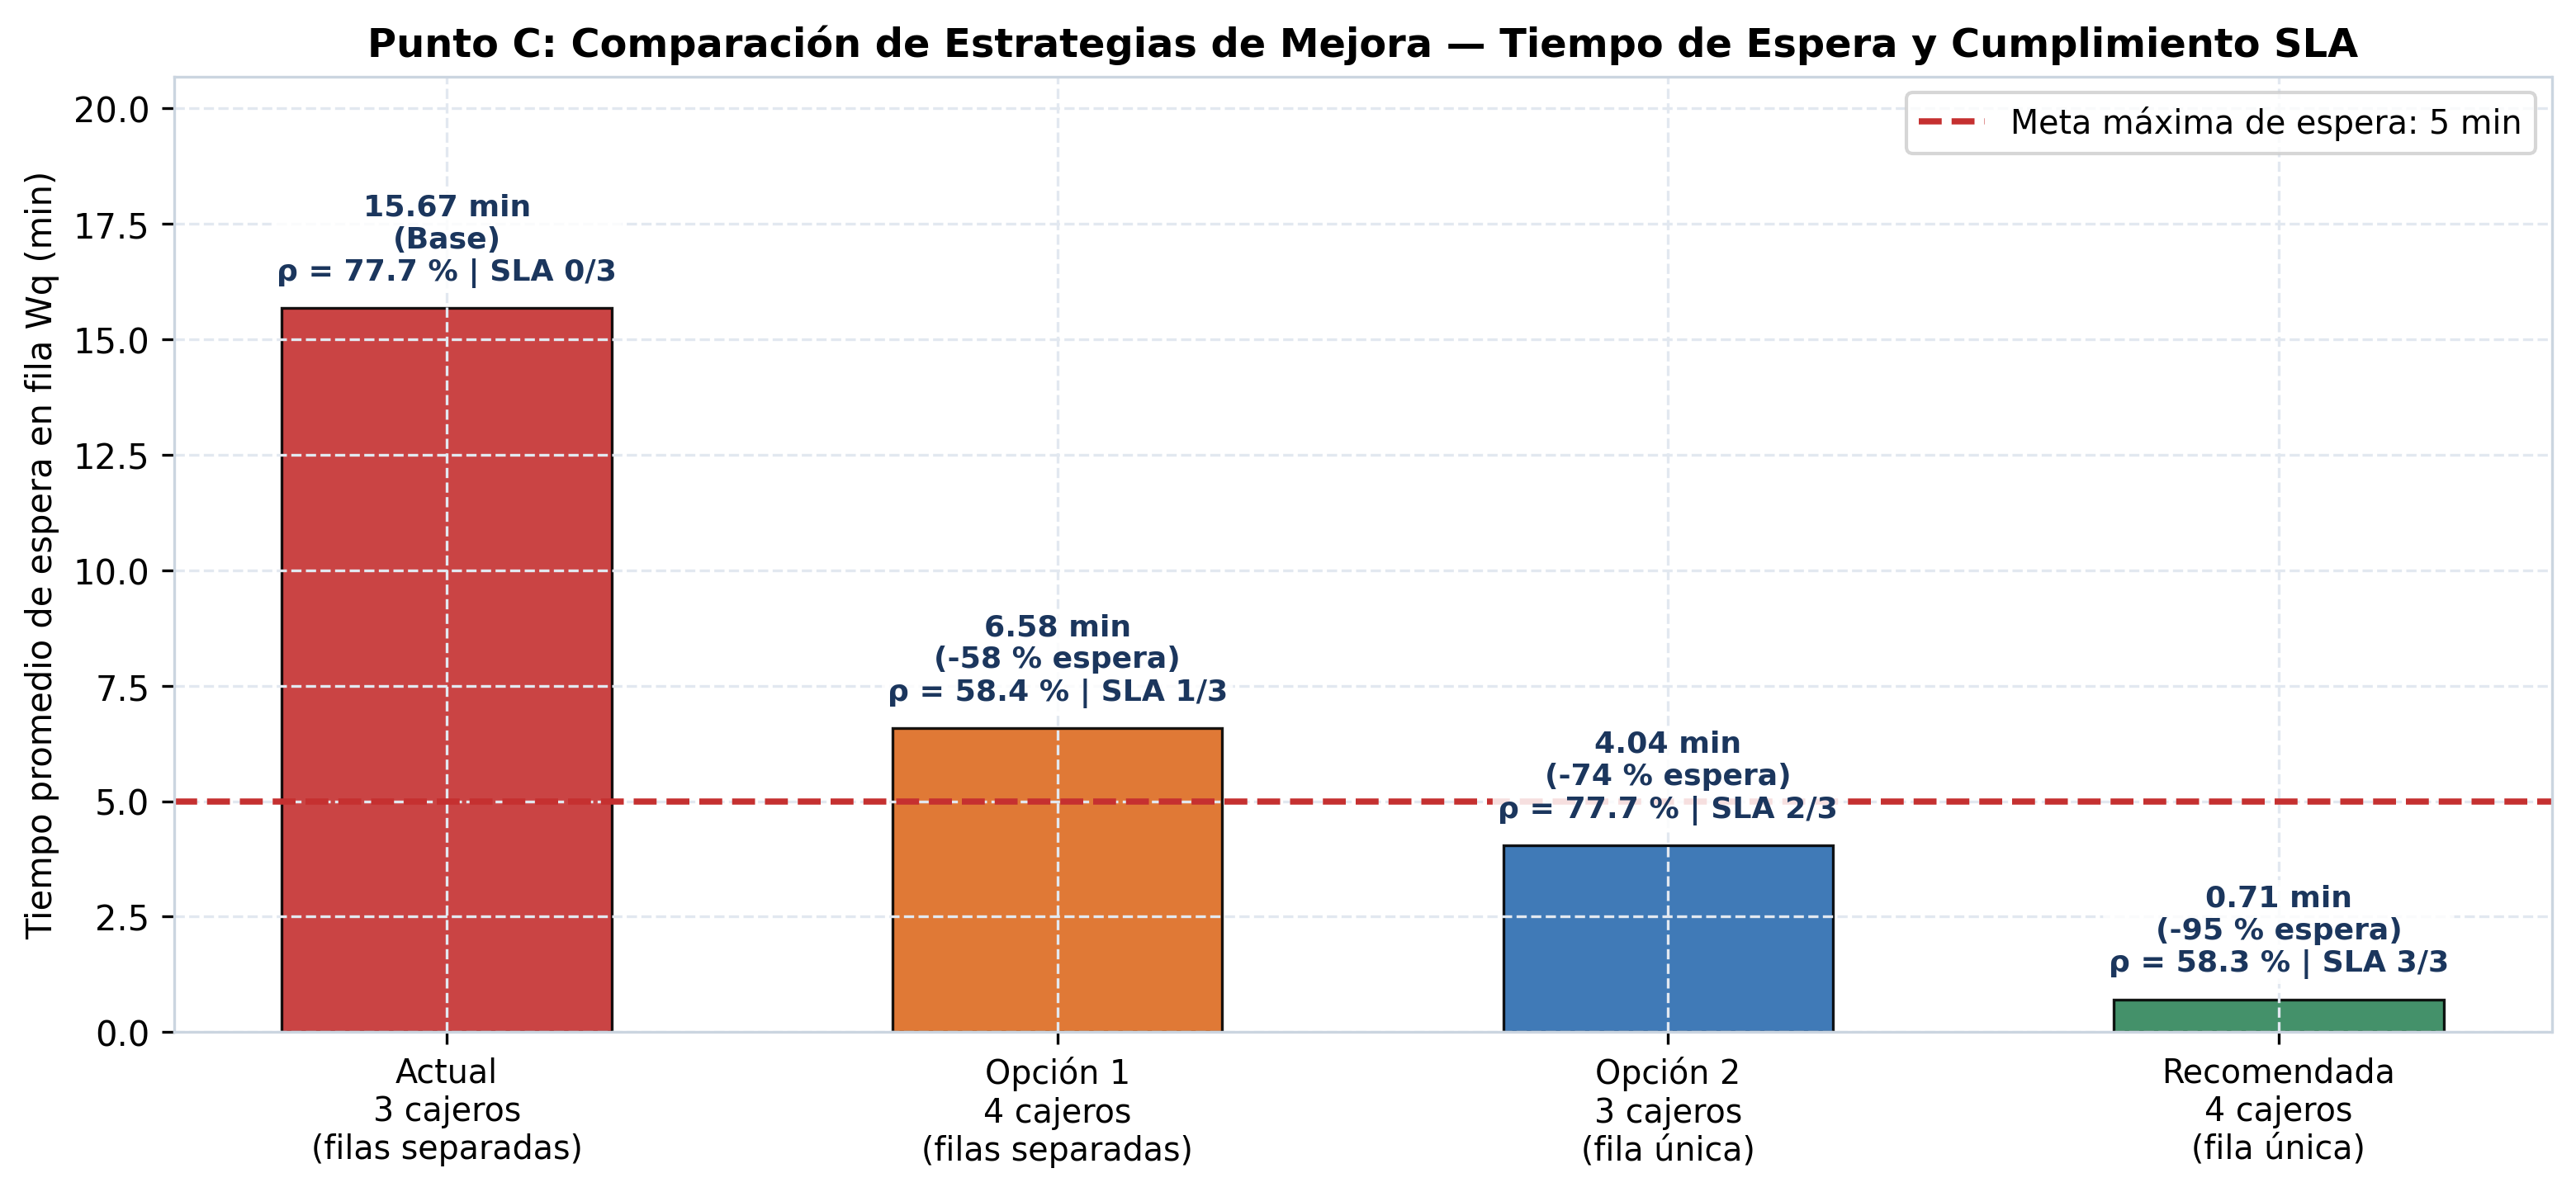

In [5]:
df_esc = evaluar_estrategias(R_OPT, T0)
display(df_esc[['Escenario', 'Espera_Wq_min', 'Total_W_min', 'Utilizacion_pct', 'Reduccion_Wq_pct', 'Criterios_SLA']].round(2))
display(Image(filename=str(graficar_estrategias(df_esc, OUT_FIG)), width=800))

## 6. Punto D — Verificación, Calibración y Validación

Error Ley de Little: 0.87 %


,Metrica,Teorico_MM1,Simulado_SimPy,Error_pct
0,Servicio S (min),3.600,3.600,0.009
1,Utilización ρ,0.774,0.773,0.138
2,Espera Wq (min),12.343,12.283,0.484
3,Sistema W (min),15.943,15.883,0.377
4,Cola Lq (usr),2.654,2.647,0.281


,Reparto,rho_pct,Wq_min
0,35% Lento / 20% Muy lento,76.46,14.18
1,27.5% Lento / 27.5% Muy lento,77.17,15.04
2,20% Lento / 35% Muy lento,78.81,17.18


,Escenario_carga,rho_pct,Wq_min
0,Demanda baja (70%),53.71,5.31
1,Demanda base (100%),77.70,15.99
2,Demanda alta (110%),84.47,22.66


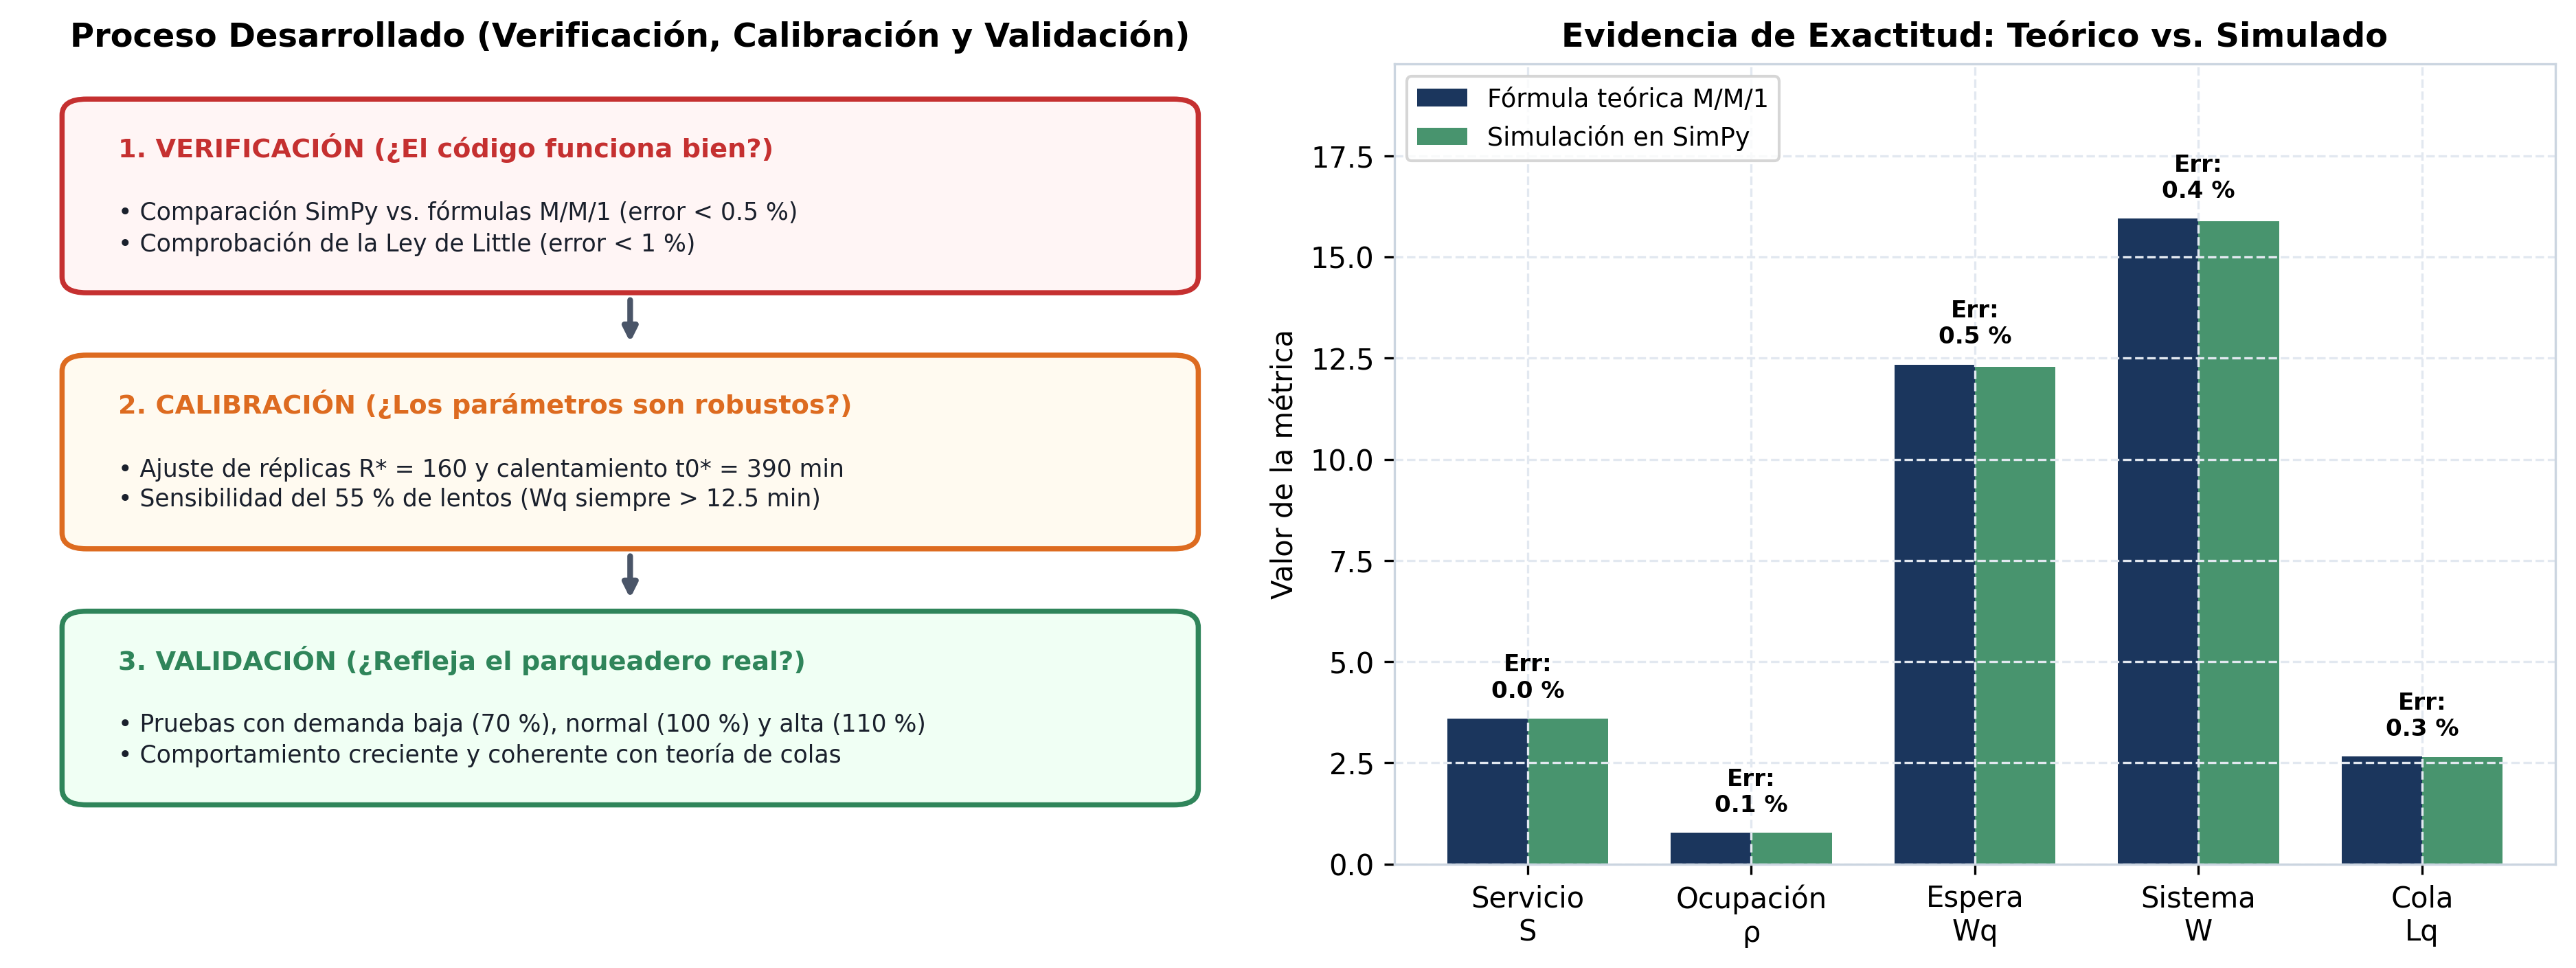

In [6]:
res_vcv = validar_modelo_vcv(res_t['df_despues'], T0)
print(f"Error Ley de Little: {res_vcv['error_little_pct']:.2f} %")
display(res_vcv['df_verificacion'].round(3))
display(res_vcv['df_calibracion'].round(2))
display(res_vcv['df_validacion'].round(2))
display(Image(filename=str(graficar_vcv(res_vcv, OUT_FIG)), width=840))

## 7. Conclusión Final
- **3 cajeros independientes no alcanzan** (`Wq = 15.67 min`, 0/3 criterios).
- **Acción inmediata sin comprar equipos:** pasar los 3 cajeros a **fila única** baja la espera un **74.2 %** (`4.04 min`).
- **Estrategia óptima recomendada:** **4 cajeros con fila única** (`Wq = 0.71 min`, **-95.5 %**, ocupación `58.3 %`, cumple **3/3 criterios**).